# Oscillatory Modes and Embedding Dimension

Generate AR signals with one, two, and three oscillatory pole pairs. Inspect their delay embeddings, compare the PCA dimensions needed to explain 95% of variance, and estimate pole pairs with fitted AR models. Finally, embed a signal whose AR coefficients vary over time.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import neuralfieldmanifold as nfm

configurations = [([10.], [.95]), ([10., 30.], [.95, .90]), ([8., 20., 45.], [.95, .92, .88])]
signals = []
for frequencies, radii in configurations:
    coefficients = nfm.simulation.coefficients_from_modes(frequencies, radii, sampling_rate_hz=1000)
    x = nfm.simulation.ar(coefficients, n_samples=10000, noise_std=.3, seed=42)
    signals.append(x)


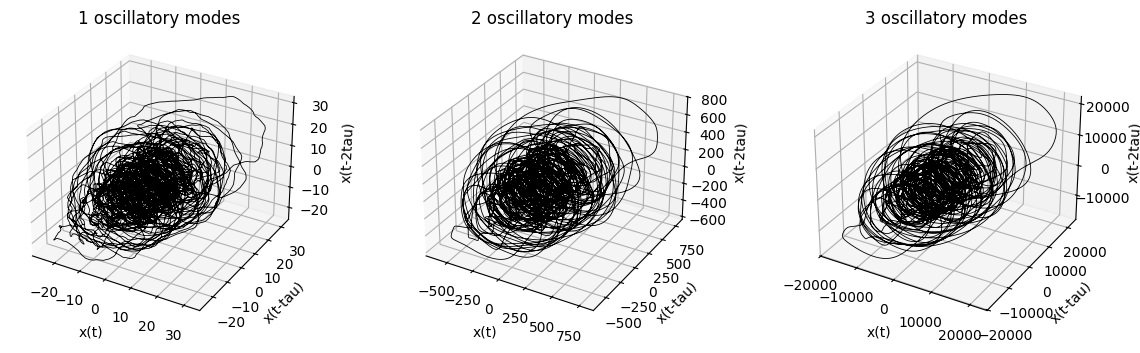

In [2]:
fig = plt.figure(figsize=(12, 3.5))
for i, x in enumerate(signals):
    cloud = nfm.embedding.delay(x, dimension=6, tau_samples=15)
    ax = fig.add_subplot(1, 3, i + 1, projection='3d')
    nfm.plotting.embedding(cloud[:, :3], ax=ax)
    ax.set_title(f'{i + 1} oscillatory modes')
plt.tight_layout()
plt.show()


In [3]:
for x, (frequencies, radii) in zip(signals, configurations):
    hankel = np.lib.stride_tricks.sliding_window_view(x, 100)
    pca = PCA().fit(hankel)
    dimension = np.searchsorted(np.cumsum(pca.explained_variance_ratio_), .95) + 1
    order = 2 * len(frequencies)
    fit = nfm.models.AR(order=order).fit(x)
    modes = fit.poles[(np.abs(fit.poles.imag) > 1e-6) & (fit.poles.imag > 0)]
    print('PCA dimension:', dimension, 'oscillatory pole pairs:', len(modes))


PCA dimension: 5 oscillatory pole pairs: 1
PCA dimension: 5 oscillatory pole pairs: 2
PCA dimension: 5 oscillatory pole pairs: 3


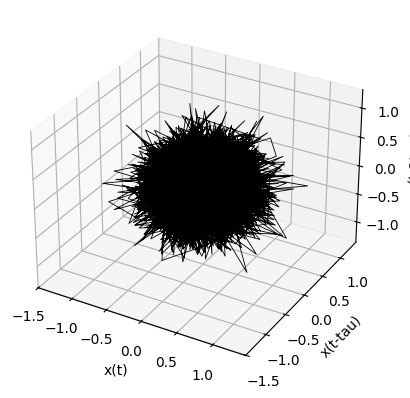

In [4]:
coefficients = nfm.simulation.schedules.sinusoid(10000, 4, np.random.default_rng(0))
x = nfm.simulation.tvar(coefficients, noise_std=.3, seed=42, burn_in_samples=500, target_power=None)
cloud = nfm.embedding.delay(x, dimension=6, tau_samples=15)
nfm.plotting.embedding(cloud[:, :3])
plt.show()
